# Milestone 1 ? verified dataset exploration

No training runs in this notebook. Sources are pinned to revision `07371b25b9cdd830638c4ffd5ed8b8a150d7f696`. Run `scripts/inspect_dataset.py` then `scripts/run_eda.py` to regenerate the underlying results. The original notebook is preserved in the takeover backup under `scratch/`.

**Attribution:** Isolated Guitar Chords by rodriler (derived from severyn-k), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/), [source](https://huggingface.co/datasets/rodriler/isolated-guitar-chords). Processing changes: decoding, mono conversion, resampling, activity crop and spectral visualization.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import display, Image
root=Path.cwd()
if root.name != "ml": root=root/"ml"
sys.path.insert(0,str(root))
assert Path(sys.executable).resolve() == (root/".venv/Scripts/python.exe").resolve(), sys.executable
report=json.loads((root/"data/dataset_inspection_report.json").read_text())
assert report["inventory_verified"] and report["eda_verified"]
print("Interpreter:",sys.executable)
print("Revision:",report["revision"])
print("Splits:",report["splits"],"Classes:",report["class_count"])

Interpreter: C:\Users\harsh\Downloads\Coding\Chordly\ml\.venv\Scripts\python.exe
Revision: 07371b25b9cdd830638c4ffd5ed8b8a150d7f696
Splits: {'train': 633, 'test': 147} Classes: 25


## 1. Actual labels and counts

The card is a hypothesis to check. Am and E each have 15 additional GarageBand recordings. Noise has only three original recordings per split; dividing long recordings into windows will not create independent recordings.

,train,test
A,25,6
A#,25,6
A#m,25,6
Am,40,6
B,25,6
Bm,25,6
C,25,6
C#,25,6
C#m,25,6
Cm,25,6


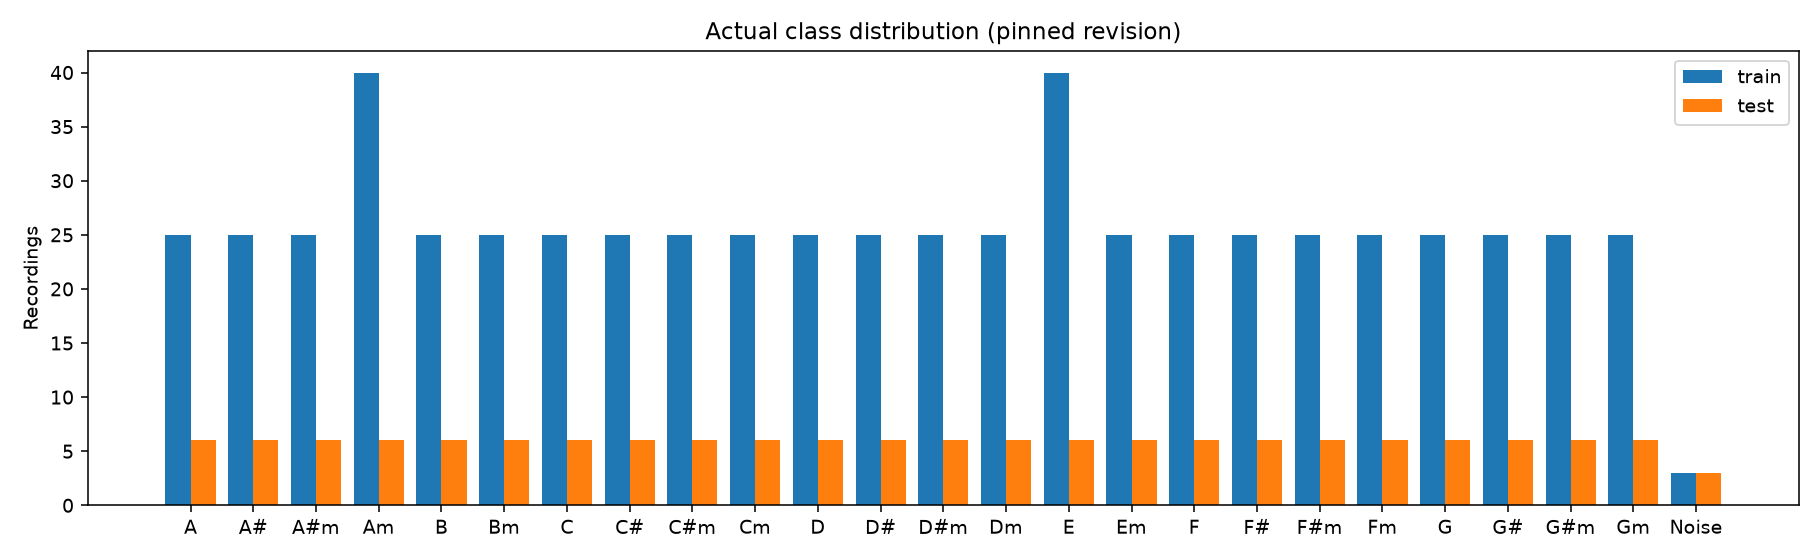

Compatibility:


,canonical,supported,reason
A,A,True,supported
A#,A#,True,supported
A#m,A#m,True,supported
Am,Am,True,supported
B,B,True,supported
Bm,Bm,True,supported
C,C,True,supported
C#,C#,True,supported
C#m,C#m,True,supported
Cm,Cm,True,supported


In [2]:
display(pd.DataFrame(report["per_class_counts"]))
display(Image(filename=str(root/"data/eda_output/class_distribution.png")))
print("Compatibility:")
display(pd.DataFrame(report["canonical_compatibility"]["labels"]).T)

## 2. Audio formats, duration and integrity

SoundFile reads original WAV headers and samples directly, avoiding the datasets.Audio / torchcodec interface. Hashes are checked against source LFS metadata. Exact decoded PCM duplicates and cross-split overlap are checked; similar sessions can still share acoustic characteristics. Clipping is retained and reported as a source-quality limitation, not silently repaired.

Sample rates: {'44100': 777, '48000': 1, '16000': 2} Channels: {'1': 747, '2': 33} Subtypes: {'PCM_16': 779, 'PCM_24': 1}


,train,test
n,633.000000,147.000000
min,3.851247,5.008617
median,5.567347,5.687075
mean,5.805614,6.626180
p95,6.146032,6.221859
max,51.200000,60.796937


Invalid files: 0 Duplicate groups: 0
Recordings with >1% clipped samples: 65


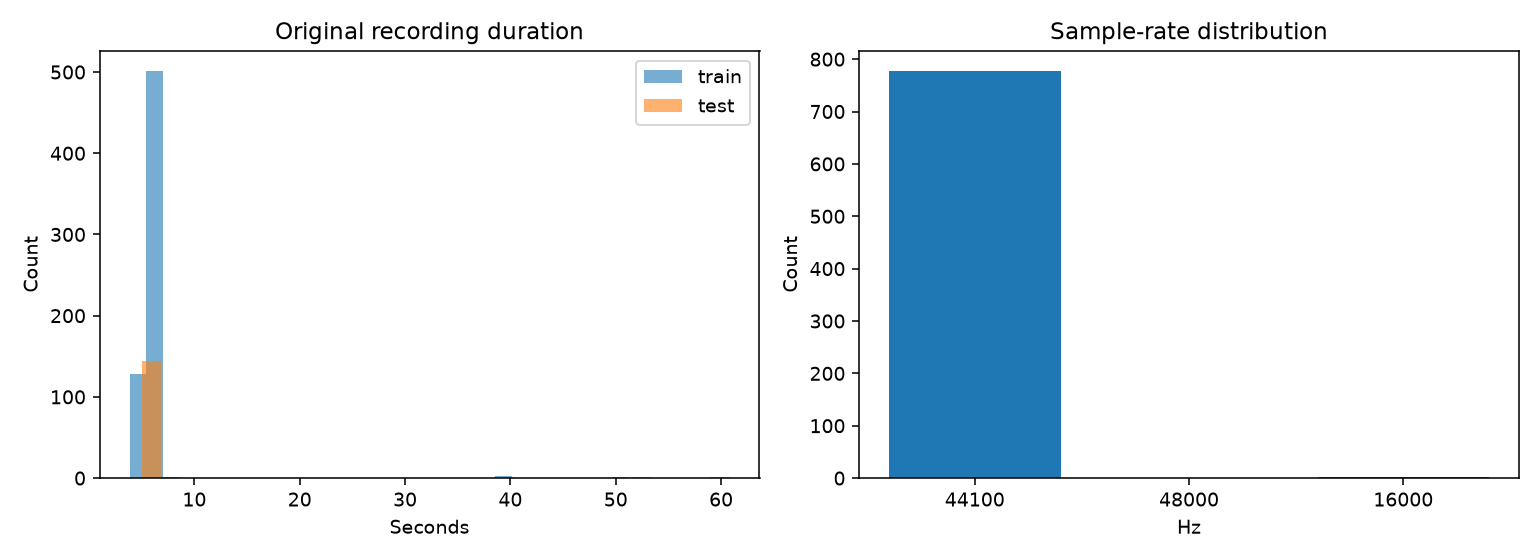

In [3]:
print("Sample rates:",report["sample_rates"],"Channels:",report["channels"],"Subtypes:",report["subtypes"])
display(pd.DataFrame(report["duration_summary"]))
print("Invalid files:",len(report["errors"]),"Duplicate groups:",len(report["duplicate_pcm_groups"]))
print("Recordings with >1% clipped samples:",len(report["source_quality_flags"]))
display(Image(filename=str(root/"data/eda_output/duration_distribution.png")))

## 3. Waveforms and onset

A spectral-flux onset detector can trigger on small handling sounds. Compare it with the energy gate and the visible attack. Our class-independent crop uses an absolute RMS floor plus 10% of peak frame RMS, with 40 ms pre-roll. This changes crop timing without amplifying a quiet Noise recording. No detected activity is represented explicitly rather than falsely recorded as onset zero.

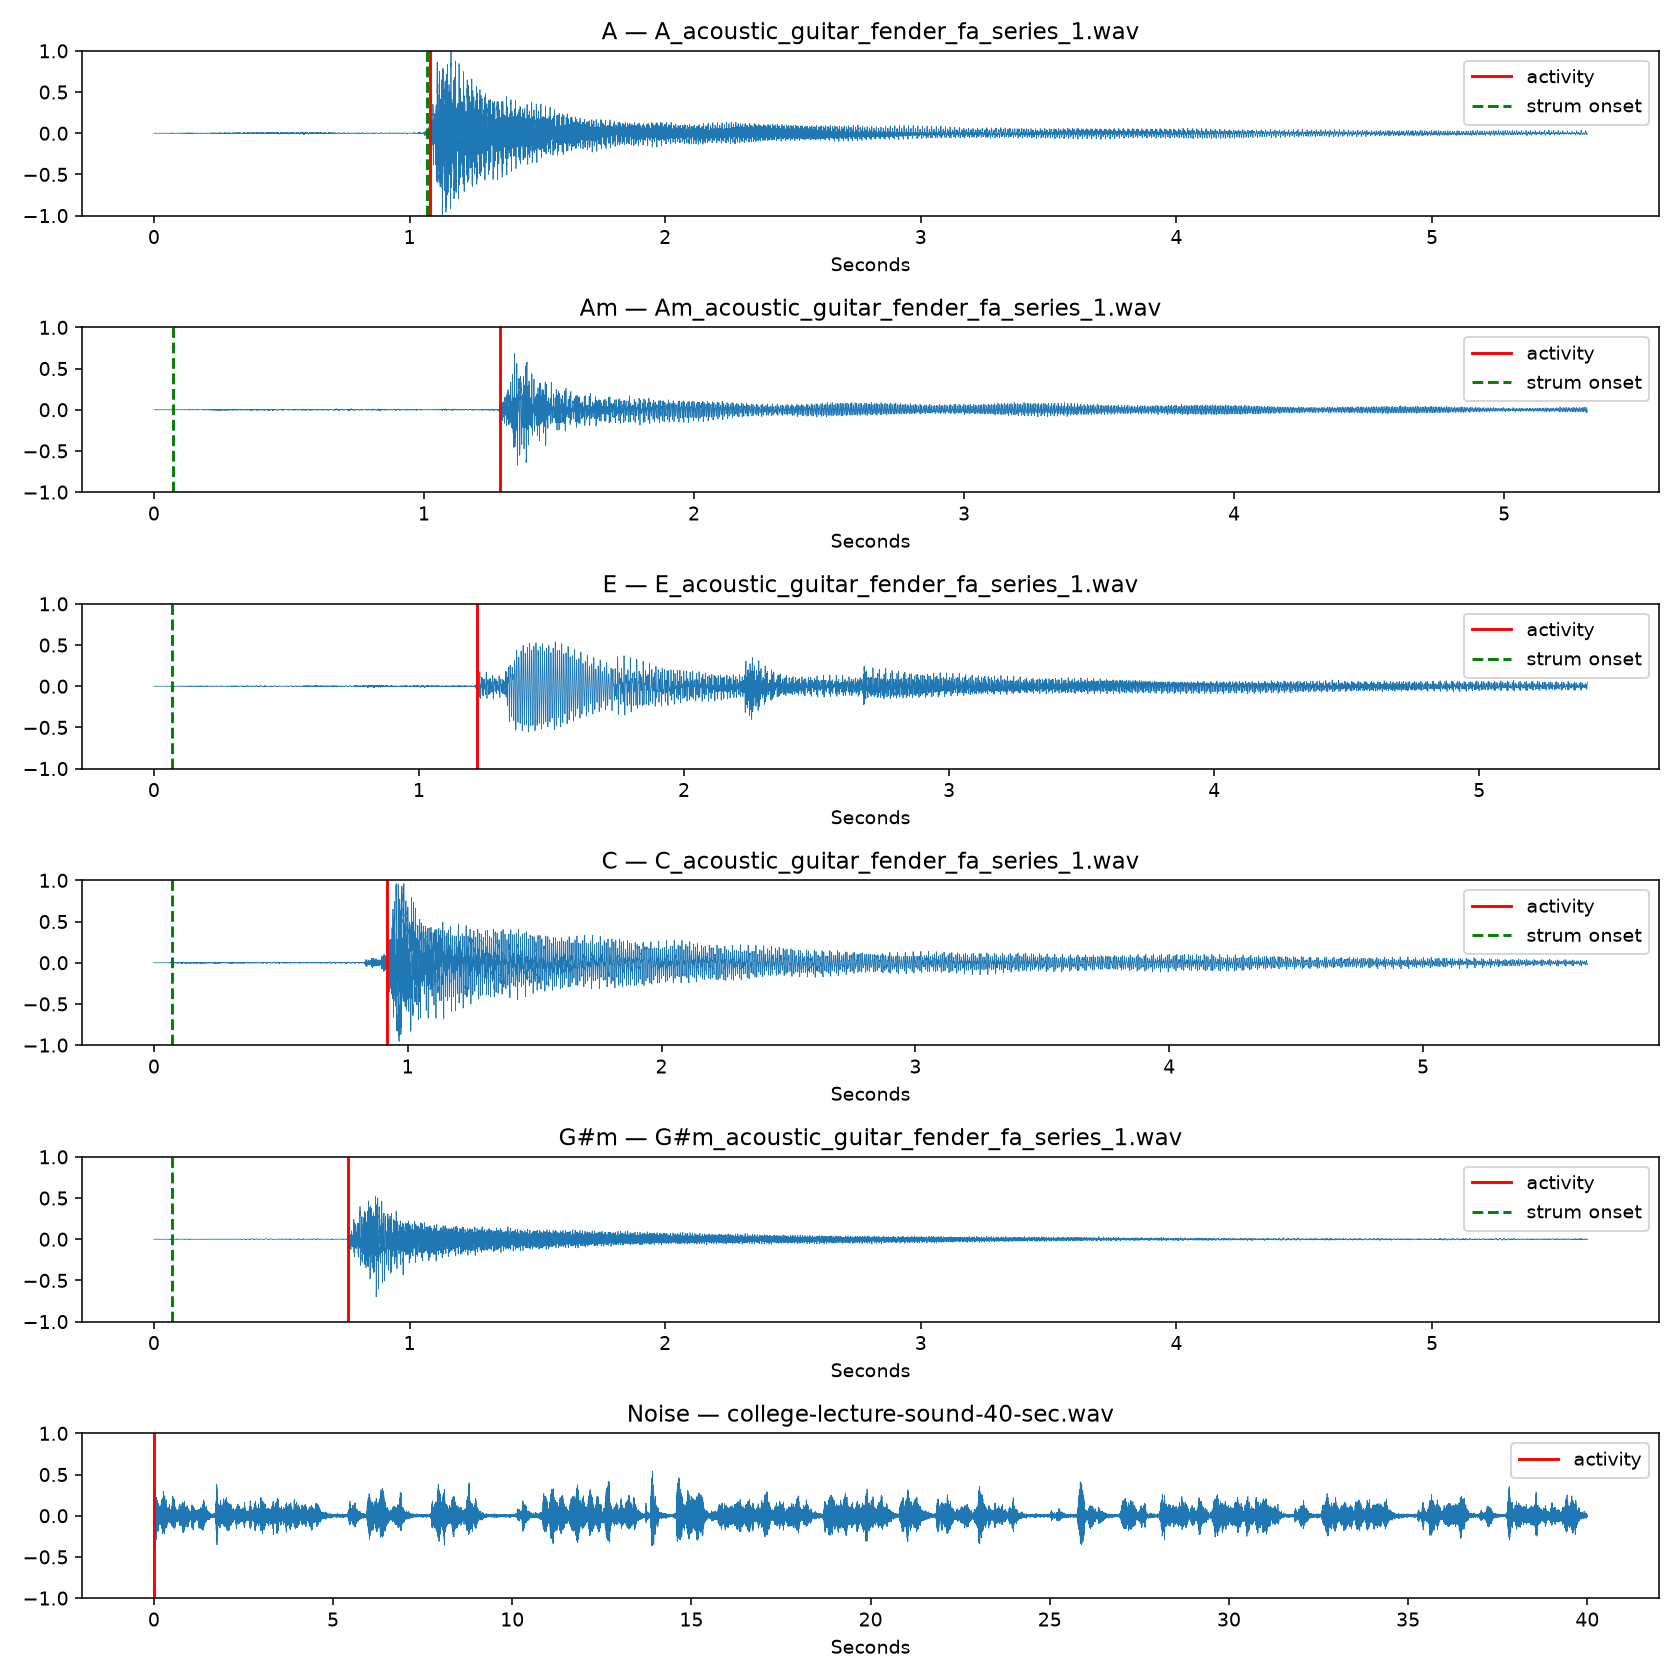

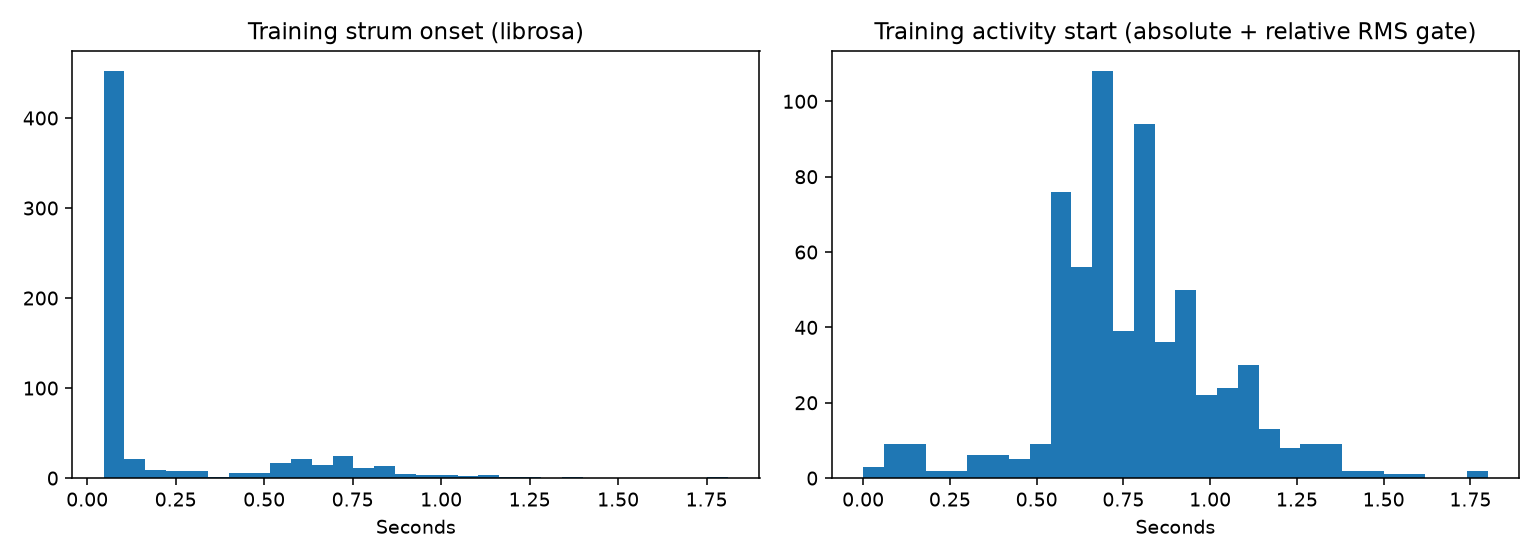

Crop configuration: {'sample_rate': 22050, 'duration': 2.0, 'activity_threshold': 0.003, 'relative_activity_threshold': 0.1, 'frame_ms': 20.0, 'preroll_ms': 40.0, 'max_input_seconds': 90.0}


In [4]:
display(Image(filename=str(root/"data/eda_output/waveform_and_onset.png")))
display(Image(filename=str(root/"data/eda_output/onset_distribution.png")))
print("Crop configuration:",report["audio_config"])

## 4. Two versus three seconds; Log-Mel versus CQT/chroma

All Log-Mel panels use ref=1, a common -100 to +30 dB scale, and identical preprocessing. We do not normalize each recording to its own peak. Mel groups frequency energy for compact learning; CQT uses musical spacing; chroma collapses octaves into 12 pitch classes. The energy summaries describe training recordings only. Select duration using training-derived validation, not official test scores.

,2,3
n,630.000000,630.000000
min,0.132828,0.373591
median,0.866062,0.946884
mean,0.736899,0.848507
p95,0.975091,0.994589
max,0.998770,0.999990


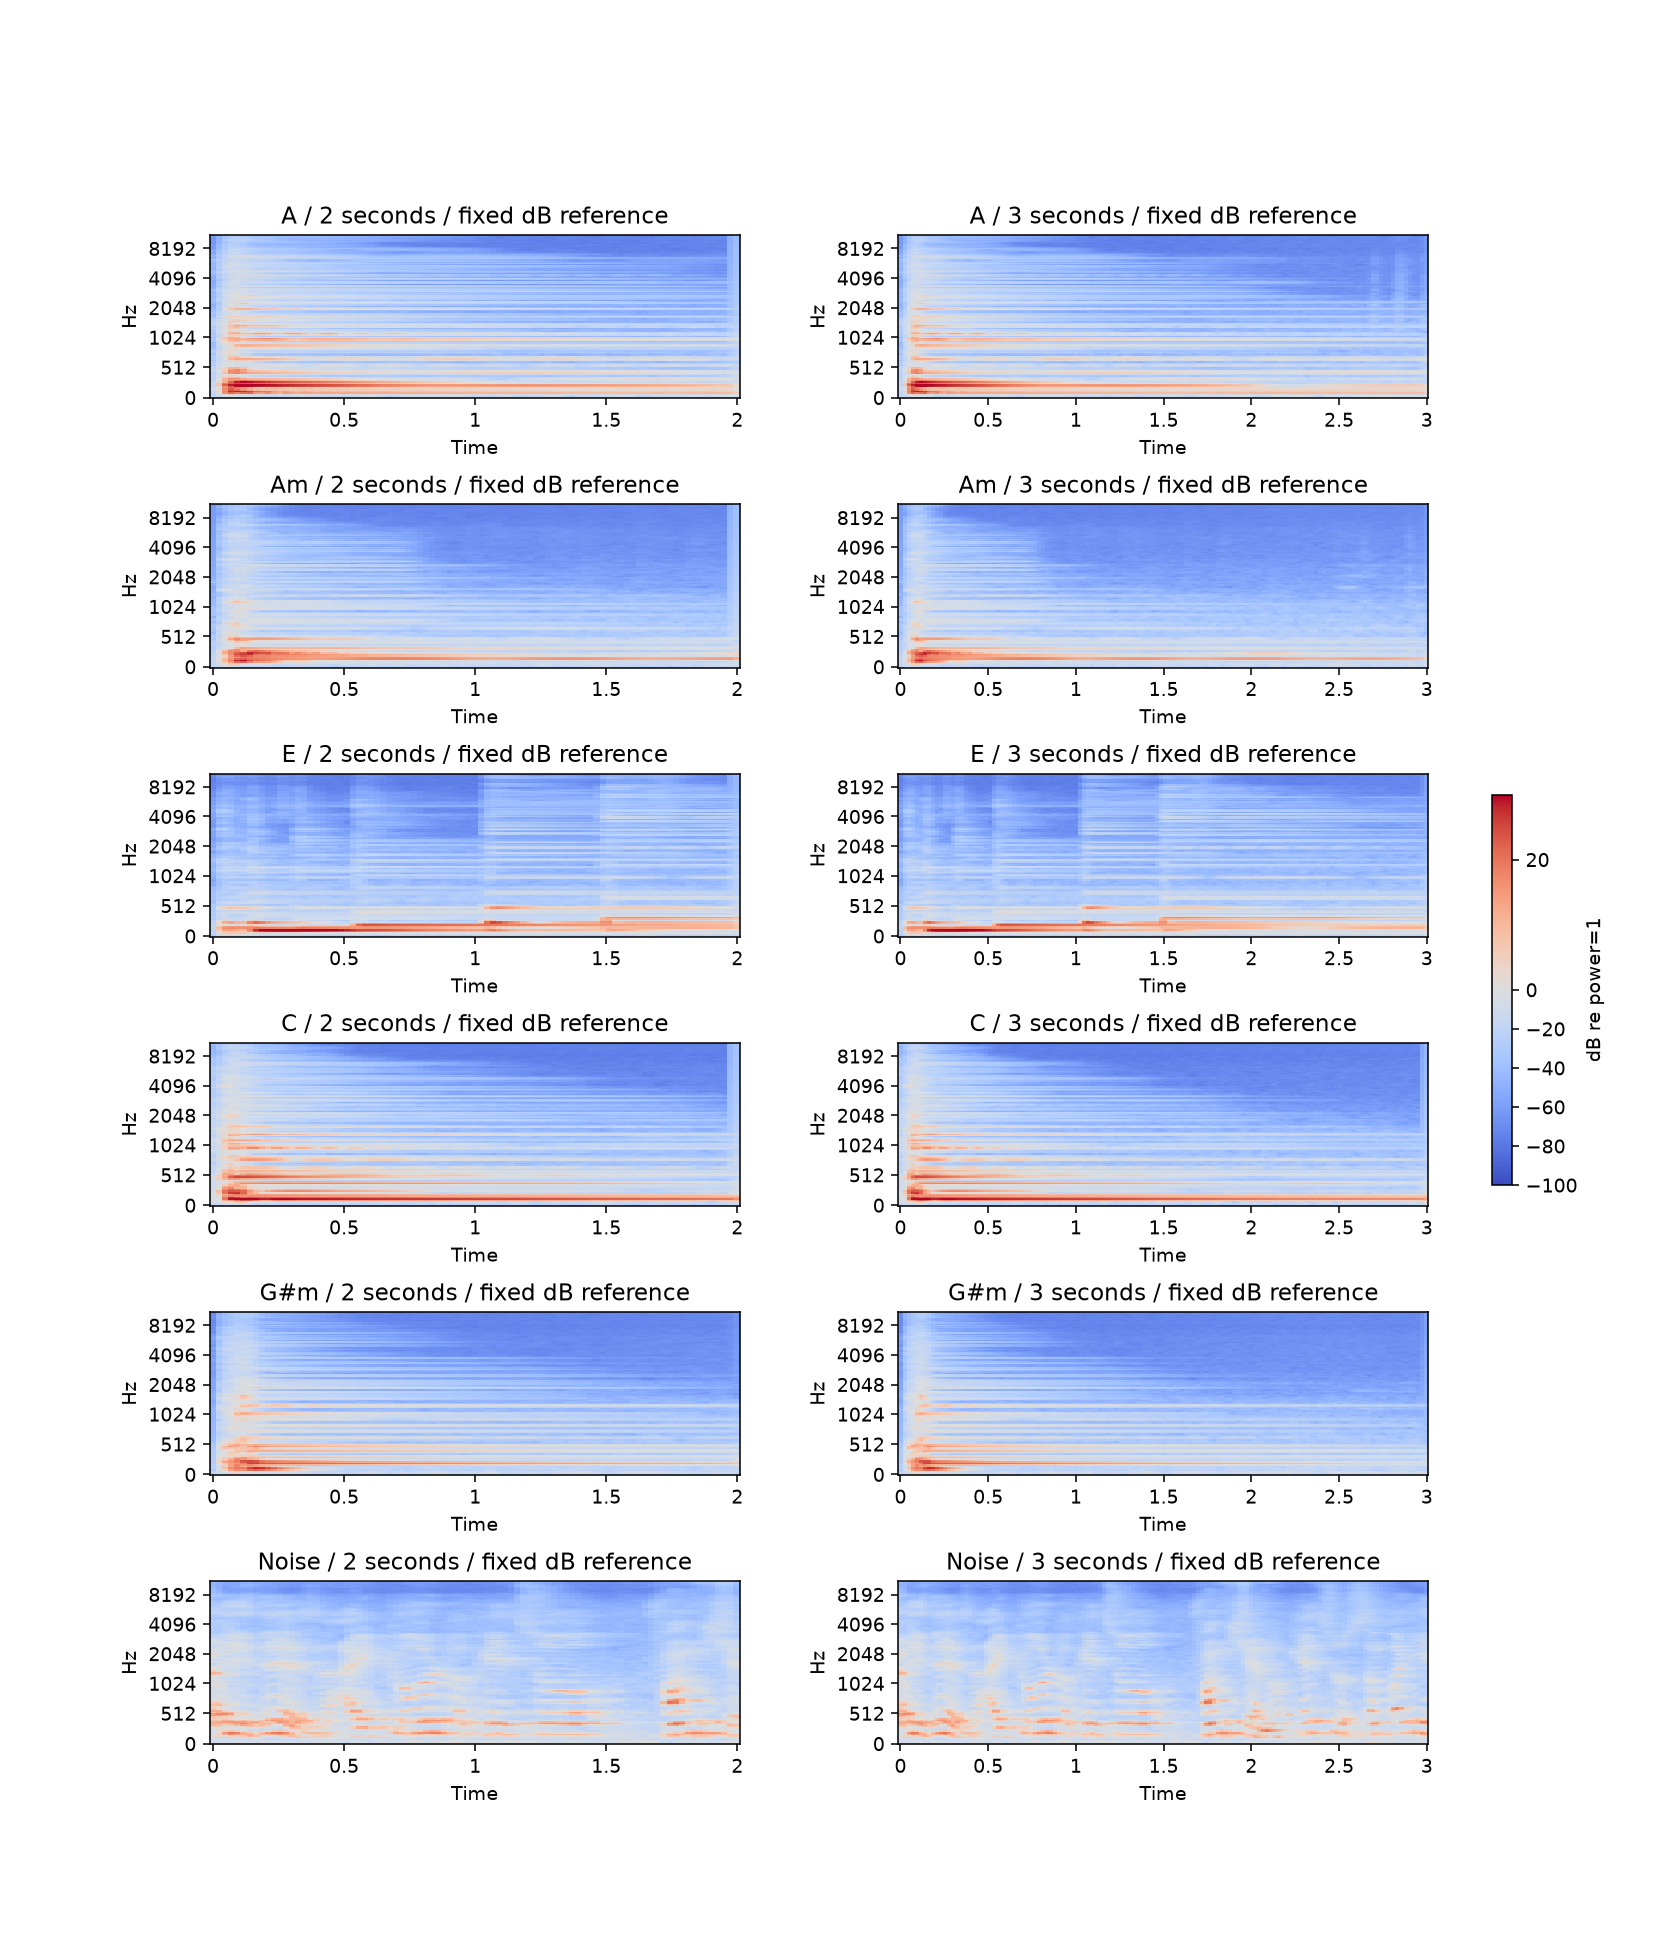

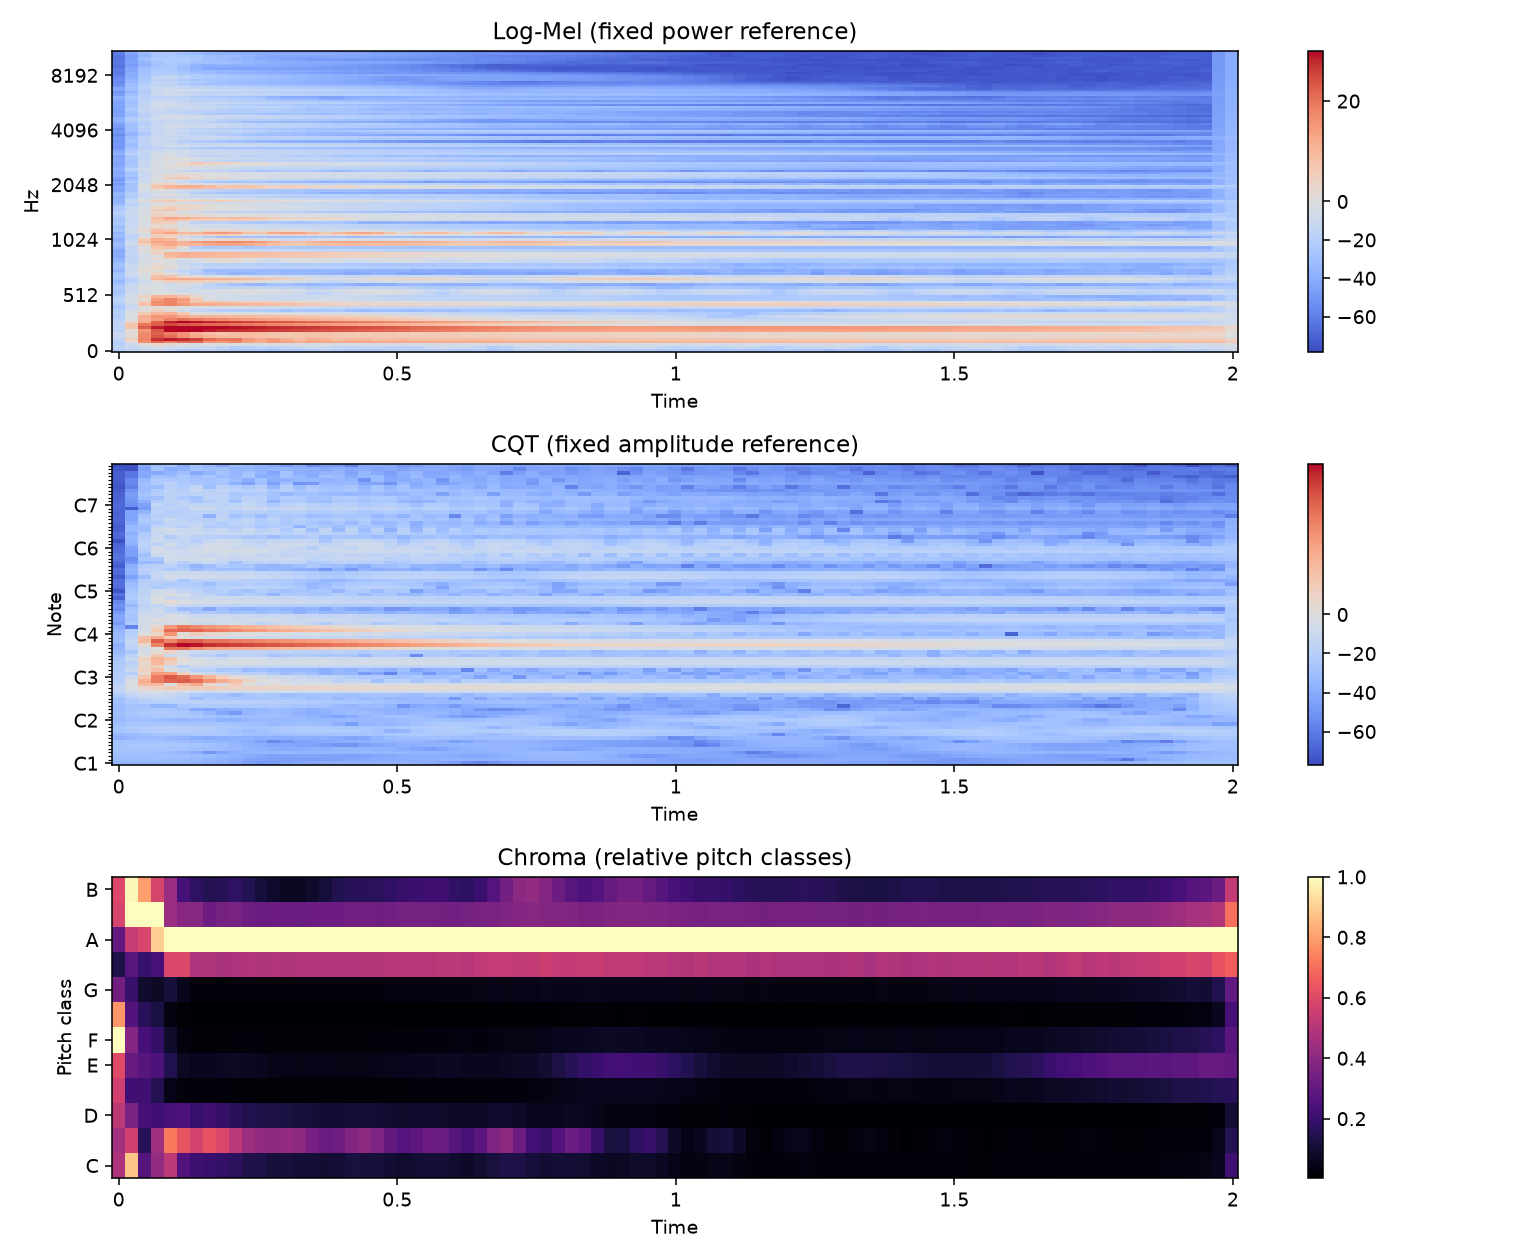

In [5]:
display(pd.DataFrame(report["window_energy_summary"]))
display(Image(filename=str(root/"data/eda_output/two_vs_three_seconds.png")))
display(Image(filename=str(root/"data/eda_output/mel_vs_cqt_vs_chroma.png")))

## 5. Noise comparison and limitations

Noise and chords use the same inference-compatible transform. Noise is not peak-normalized or blindly silence-trimmed. Dataset-only accuracy does not establish performance on a new guitar or microphone. D#m is a valid source class but lacks a frontend fingering: future inference must report it as unsupported rather than altering the catalog. Do not start training until this report, plots, and tests have been reviewed.

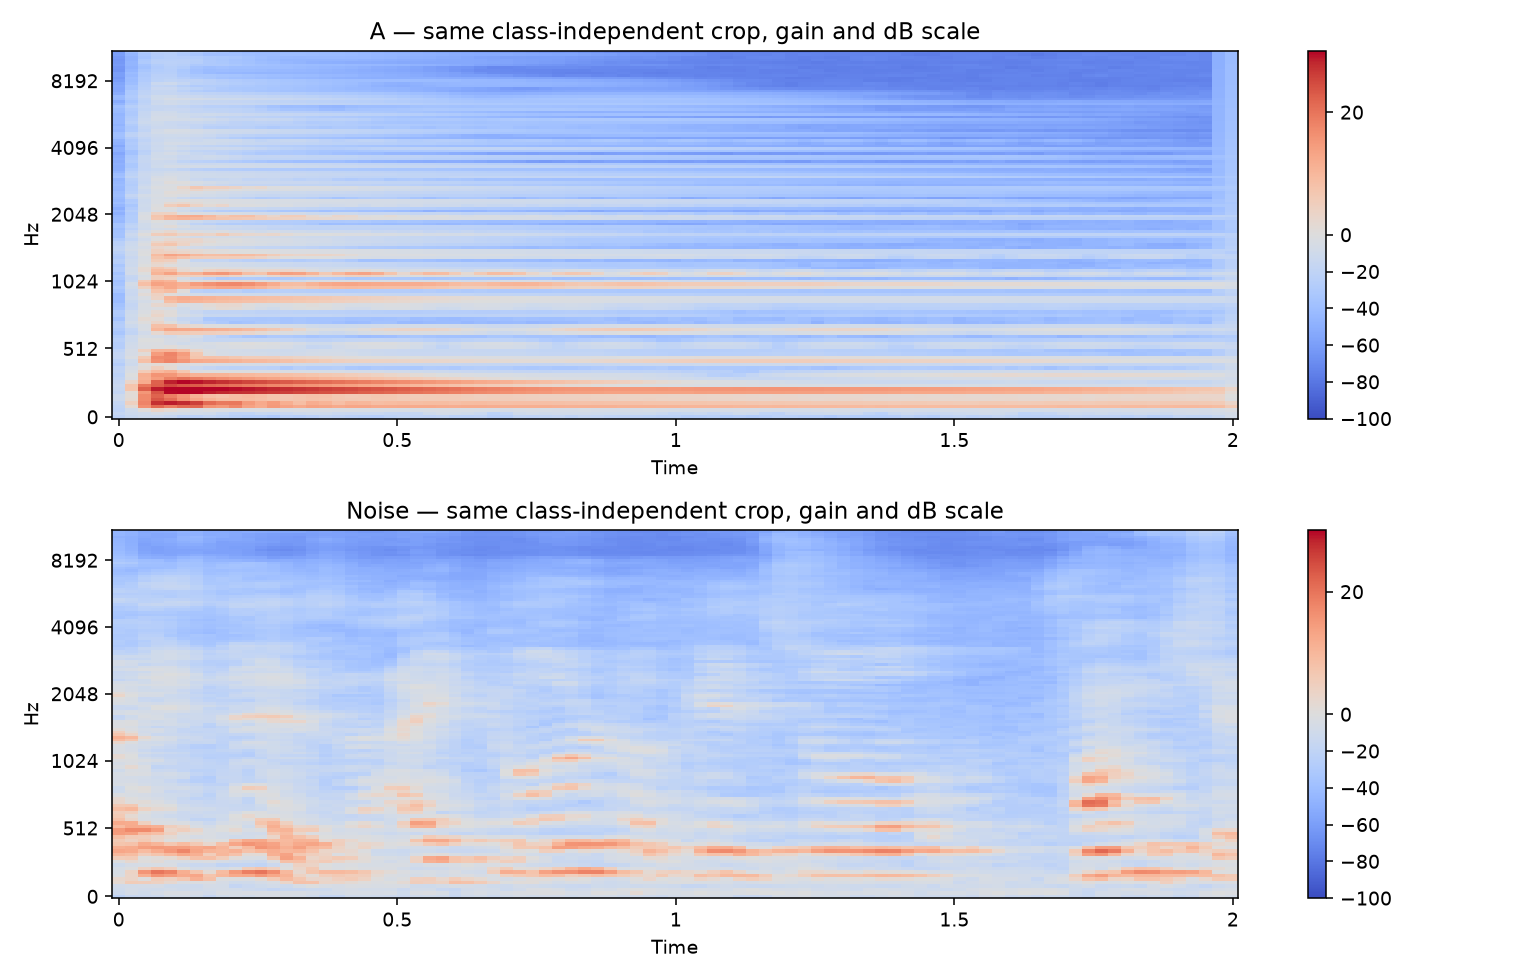

- Only 3 Noise examples per official split: noise metrics have high uncertainty.
- Am and E each include 15 GarageBand files, explaining 40 rather than 25 training examples.
- Fender source is a single guitar/player; filename take numbers do not establish independent recording sessions.
- Exact PCM hashing detects duplicates, not all related or nearly identical takes.
- Official test waveforms are inspected for integrity only; EDA figures and choices use training audio.
Inventory gate: True EDA gate: True


In [6]:
display(Image(filename=str(root/"data/eda_output/chord_vs_noise.png")))
for limitation in report["limitations"]: print("-",limitation)
print("Inventory gate:",report["inventory_verified"],"EDA gate:",report["eda_verified"])